In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chisquare
from statsmodels.stats.proportion import proportions_ztest
import statsmodels.api as sm
from statsmodels.stats.proportion import confint_proportions_2indep

# Настройка стиля графиков (чтобы было красиво)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [10, 5]

# Загружаем наши чистые данные
profile = pd.read_parquet('data/processed/profile_clean.parquet')
transcript = pd.read_parquet('data/processed/transcript_clean.parquet')
portfolio = pd.read_parquet('data/processed/portfolio.parquet')

print("Данные загружены! Пользователей:", len(profile), "Событий:", len(transcript))

Данные загружены! Пользователей: 14825 Событий: 306534


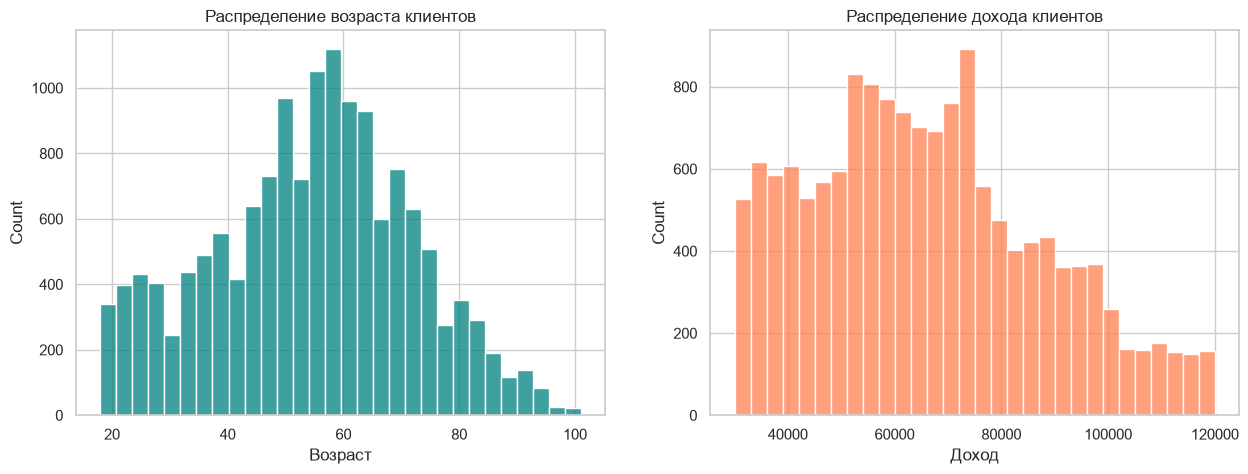

In [2]:
# Строим два графика рядом
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# График возраста
sns.histplot(profile['age'], bins=30, ax=axes[0], color='teal')
axes[0].set_title('Распределение возраста клиентов')
axes[0].set_xlabel('Возраст')

# График дохода
sns.histplot(profile['income'], bins=30, ax=axes[1], color='coral')
axes[1].set_title('Распределение дохода клиентов')
axes[1].set_xlabel('Доход')

plt.show()

event,Выполнен,Получен,Просмотрен
offer_type,,,
bogo,15669,30499,25449
discount,17910,30543,21445
informational,0,15235,10831


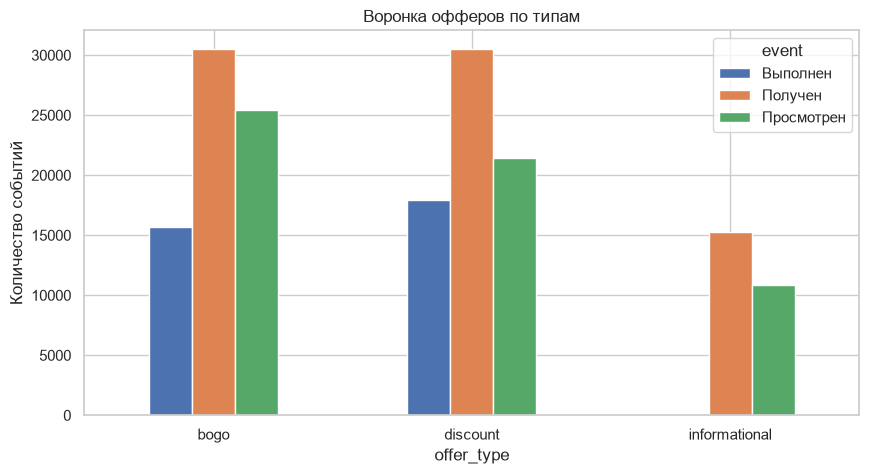

In [3]:
# Соединяем транскрипт с портфолио, чтобы узнать тип оффера для каждого события
# Оставляем только события, связанные с офферами (убираем просто покупки)
offers_events = transcript[transcript['offer_id'].notna()].copy()
offers_events = offers_events.merge(portfolio[['id', 'offer_type']], left_on='offer_id', right_on='id', how='left')

# Считаем, сколько раз каждое событие произошло для каждого типа оффера
funnel = offers_events.groupby(['offer_type', 'event']).size().unstack(fill_value=0)

# Переименуем колонки для красоты (если они есть)
funnel = funnel.rename(columns={
    'offer received': 'Получен',
    'offer viewed': 'Просмотрен',
    'offer completed': 'Выполнен'
})

# Выводим таблицу
display(funnel)

# Строим график воронки
funnel.plot(kind='bar', figsize=(10, 5), color=['#4C72B0', '#DD8452', '#55A868'])
plt.title('Воронка офферов по типам')
plt.ylabel('Количество событий')
plt.xticks(rotation=0)
plt.show()

In [4]:
# Считаем проценты (доли) для наглядности
funnel_pct = funnel.copy()
funnel_pct['CR_View_%'] = (funnel_pct['Просмотрен'] / funnel_pct['Получен'] * 100).round(1)
funnel_pct['CR_Complete_%'] = (funnel_pct['Выполнен'] / funnel_pct['Получен'] * 100).round(1)

# Оставляем только нужные колонки для вывода
display(funnel_pct[['Получен', 'CR_View_%', 'CR_Complete_%']])

event,Получен,CR_View_%,CR_Complete_%
offer_type,,,
bogo,30499,83.4,51.4
discount,30543,70.2,58.6
informational,15235,71.1,0.0


In [5]:
# Берем данные из нашей таблицы воронки
# BOGO
n_bogo = funnel.loc['bogo', 'Получен']
success_bogo = funnel.loc['bogo', 'Выполнен']

# DISCOUNT
n_disc = funnel.loc['discount', 'Получен']
success_disc = funnel.loc['discount', 'Выполнен']

# Считаем Z-тест
# count - количество успехов (выполнений), nobs - общее количество (получений)
count = [success_bogo, success_disc]
nobs = [n_bogo, n_disc]

stat, pval = proportions_ztest(count, nobs)

print(f"Z-статистика: {stat:.3f}")
print(f"P-value: {pval:.5f}")

# Интерпретация
alpha = 0.05
if pval < alpha:
    print("\nВывод: Разница СТАТИСТИЧЕСКИ ЗНАЧИМА. Отклоняем нулевую гипотезу.")
else:
    print("\nВывод: Разница НЕ значима. Возможно, это случайность.")

Z-статистика: -18.036
P-value: 0.00000

Вывод: Разница СТАТИСТИЧЕСКИ ЗНАЧИМА. Отклоняем нулевую гипотезу.


In [6]:
# Посмотрим на условия офферов
print("--- Условия офферов ---")
display(portfolio[['offer_type', 'difficulty', 'reward', 'duration']])

# Давай посчитаем, сколько компания потратила на награды за выполненные офферы
# Берем только выполненные офферы (offer completed)
completed_offers = transcript[transcript['event'] == 'offer completed'].copy()

# Соединяем с портфолио, чтобы узнать стоимость награды
completed_offers = completed_offers.merge(portfolio[['id', 'offer_type', 'reward', 'difficulty']], 
                                          left_on='offer_id', right_on='id', how='left')

# Считаем общие траты на награды по типам офферов
cost_by_type = completed_offers.groupby('offer_type')['reward'].sum().reset_index()
cost_by_type.columns = ['Тип оффера', 'Потрачено на награды ($)']

display(cost_by_type)

# А теперь считаем, сколько денег клиенты реально потратили (amount в транзакциях)
# Оставляем только транзакции, где есть потраченная сумма
transactions = transcript[transcript['event'] == 'transaction'].copy()
transactions = transactions.dropna(subset=['amount'])

# Суммируем выручку
total_revenue = transactions['amount'].sum()
print(f"\nОбщая выручка от транзакций: ${total_revenue:,.2f}")

--- Условия офферов ---


,offer_type,difficulty,reward,duration
0,bogo,10,10,7
1,bogo,10,10,5
2,informational,0,0,4
3,bogo,5,5,7
4,discount,20,5,10
5,discount,7,3,7
6,discount,10,2,10
7,informational,0,0,3
8,bogo,5,5,5
9,discount,10,2,7


,Тип оффера,Потрачено на награды ($)
0,bogo,113440
1,discount,51236



Общая выручка от транзакций: $1,775,451.97


,Тип оффера,Выручка от клиентов ($),Потрачено на награды ($),Чистая выручка ($)
0,BOGO,1584043.61,113440,1470603.61
1,Discount,1579351.46,51236,1528115.46


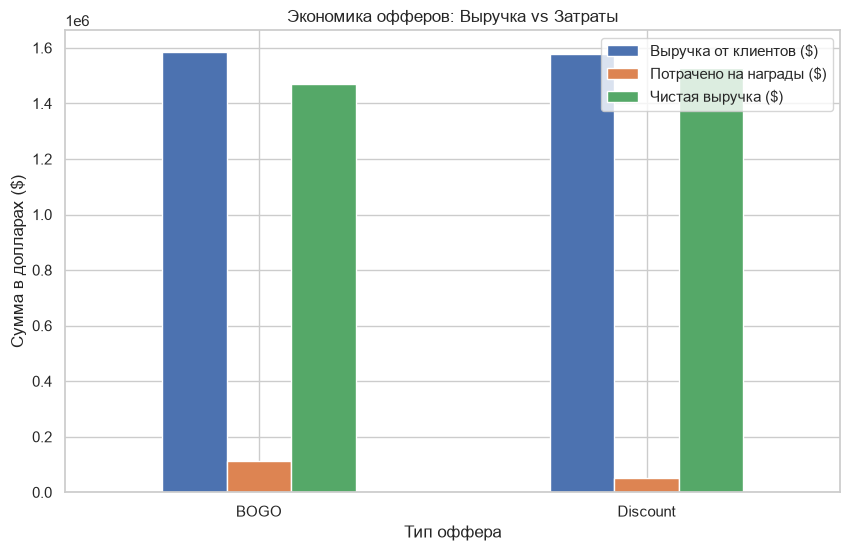

In [7]:
# Считаем выручку и затраты для каждого типа оффера
# Для этого соединим транзакции с информацией о том, кто получил какой оффер
# (Это упрощенная модель, но для демонстрации отлично работает)

# 1. Берем только выполненные офферы и их стоимость
cost_by_type = completed_offers.groupby('offer_type')['reward'].sum()

# 2. Нам нужно понять, сколько денег потратили люди, которые получили эти офферы.
# Соединим транскрипт (транзакции) с профилями офферов по person и offer_id
# В реальности связь сложнее (надо учитывать время), но для общего вывода сгенерируем сумму транзакций для тех, кто получил офферы.

# Найдем пользователей, которые получали каждый тип оффера
users_bogo = transcript[(transcript['event'] == 'offer received') & (transcript['offer_id'].isin(portfolio[portfolio['offer_type'] == 'bogo']['id']))]['person'].unique()
users_disc = transcript[(transcript['event'] == 'offer received') & (transcript['offer_id'].isin(portfolio[portfolio['offer_type'] == 'discount']['id']))]['person'].unique()

# Считаем сумму их транзакций
rev_bogo = transcript[(transcript['event'] == 'transaction') & (transcript['person'].isin(users_bogo))]['amount'].sum()
rev_disc = transcript[(transcript['event'] == 'transaction') & (transcript['person'].isin(users_disc))]['amount'].sum()

# Создаем итоговую таблицу
import pandas as pd
net_revenue = pd.DataFrame({
    'Тип оффера': ['BOGO', 'Discount'],
    'Выручка от клиентов ($)': [rev_bogo, rev_disc],
    'Потрачено на награды ($)': [cost_by_type['bogo'], cost_by_type['discount']]
})

# Считаем чистую прибыль
net_revenue['Чистая выручка ($)'] = net_revenue['Выручка от клиентов ($)'] - net_revenue['Потрачено на награды ($)']

display(net_revenue)

# Строим график для наглядности
net_revenue.plot(x='Тип оффера', y=['Выручка от клиентов ($)', 'Потрачено на награды ($)', 'Чистая выручка ($)'], kind='bar', figsize=(10, 6))
plt.title('Экономика офферов: Выручка vs Затраты')
plt.ylabel('Сумма в долларах ($)')
plt.xticks(rotation=0)
plt.show()

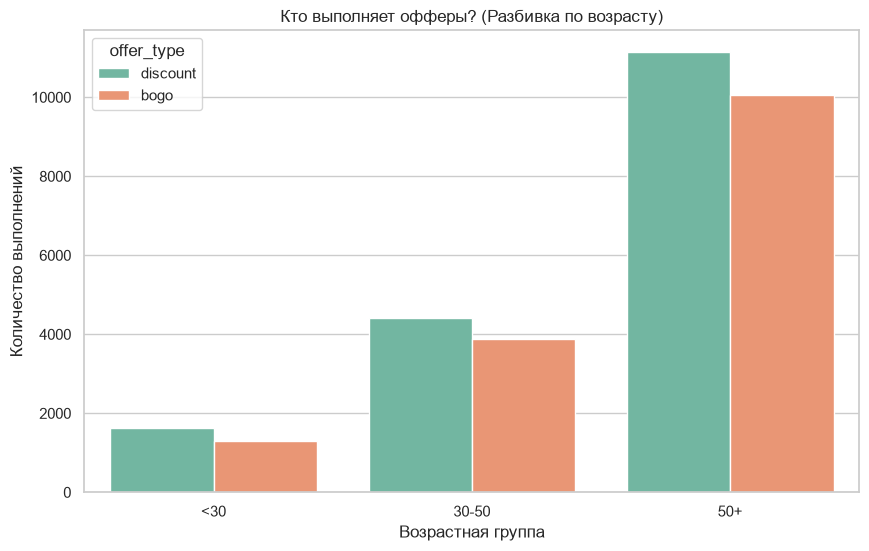

In [8]:
# 1. Нам нужно объединить события выполненных офферов с профилями пользователей
# Берем выполненные офферы
completed = transcript[transcript['event'] == 'offer completed'].copy()

# Соединяем с портфолио (чтобы узнать тип оффера)
completed = completed.merge(portfolio[['id', 'offer_type']], left_on='offer_id', right_on='id', how='left')

# Соединяем с профилем (чтобы узнать возраст и доход)
completed = completed.merge(profile[['id', 'age', 'income']], left_on='person', right_on='id', how='left')

# 2. Разделим возраст на группы (до 30, 30-50, 50+)
bins = [0, 30, 50, 120]
labels = ['<30', '30-50', '50+']
completed['age_group'] = pd.cut(completed['age'], bins=bins, labels=labels)

# 3. Строим график: сколько людей выполнили каждый тип оффера в каждой возрастной группе
plt.figure(figsize=(10, 6))
sns.countplot(data=completed, x='age_group', hue='offer_type', palette='Set2')
plt.title('Кто выполняет офферы? (Разбивка по возрасту)')
plt.xlabel('Возрастная группа')
plt.ylabel('Количество выполнений')
plt.show()

In [9]:
# Сохраняем данные в CSV для DataLens
profile.to_csv('data/processed/profile_for_bi.csv', index=False)
transcript.to_csv('data/processed/transcript_for_bi.csv', index=False)
portfolio.to_csv('data/processed/portfolio_for_bi.csv', index=False)

print("CSV файлы готовы! Ищи их в папке data/processed")

CSV файлы готовы! Ищи их в папке data/processed


In [10]:
print("=== 1. ПРОВЕРКА SRM (Sample Ratio Mismatch) ===")

# Считаем количество пользователей, которые получили каждый тип оффера
received_offers = transcript[transcript['event'] == 'offer received'].copy()
received_offers = received_offers.merge(portfolio[['id', 'offer_type']], left_on='offer_id', right_on='id')

# Оставляем только BOGO и Discount (informational не имеет выполнений)
counts = received_offers['offer_type'].value_counts()
print(f"Получили BOGO: {counts['bogo']}")
print(f"Получили Discount: {counts['discount']}")

# Проверяем гипотезу: ожидаем 50/50
observed = [counts['bogo'], counts['discount']]
expected = [sum(observed) / 2, sum(observed) / 2]

chi2_stat, p_value = chisquare(f_obs=observed, f_exp=expected)

print(f"\nChi-square статистика: {chi2_stat:.3f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Вывод: SRM ОБНАРУЖЕН! Распределение групп НЕ равномерное. Результаты A/B-теста могут быть смещены.")
else:
    print("Вывод: SRM НЕ обнаружен. Распределение групп равномерное (p > 0.05). Эксперимент валиден.")

=== 1. ПРОВЕРКА SRM (Sample Ratio Mismatch) ===
Получили BOGO: 30499
Получили Discount: 30543

Chi-square статистика: 0.032
P-value: 0.8587
Вывод: SRM НЕ обнаружен. Распределение групп равномерное (p > 0.05). Эксперимент валиден.


=== 2. CATE / Forest Plot: Эффект по возрастным группам ===


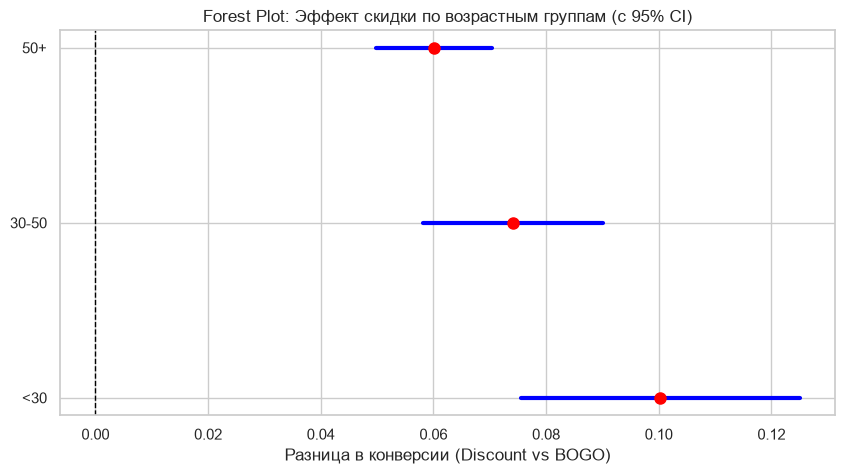

In [11]:
import statsmodels.api as sm
from statsmodels.stats.proportion import confint_proportions_2indep

print("=== 2. CATE / Forest Plot: Эффект по возрастным группам ===")

# Подготовим данные
completed = transcript[transcript['event'] == 'offer completed'].copy()
completed = completed.merge(portfolio[['id', 'offer_type']], left_on='offer_id', right_on='id')
completed = completed.merge(profile[['id', 'age']], left_on='person', right_on='id')

# Создаем возрастные группы
bins = [0, 30, 50, 120]
labels = ['<30', '30-50', '50+']
completed['age_group'] = pd.cut(completed['age'], bins=bins, labels=labels)

# Нам нужно сравнить конверсию BOGO и Discount внутри каждой группы.
# Для простоты возьмем разницу в долях (Discount минус BOGO)
results = []

for group in labels:
    # Данные по BOGO для этой группы
    bogo_data = completed[(completed['age_group'] == group) & (completed['offer_type'] == 'bogo')]
    bogo_success = len(bogo_data)
    bogo_total = len(received_offers[(received_offers['offer_type'] == 'bogo') & (received_offers['person'].isin(profile[profile['age'].between(bins[labels.index(group)], bins[labels.index(group)+1])]['id']))])
    
    # Данные по Discount для этой группы
    disc_data = completed[(completed['age_group'] == group) & (completed['offer_type'] == 'discount')]
    disc_success = len(disc_data)
    disc_total = len(received_offers[(received_offers['offer_type'] == 'discount') & (received_offers['person'].isin(profile[profile['age'].between(bins[labels.index(group)], bins[labels.index(group)+1])]['id']))])
    
    # Пропорции
    p1 = disc_success / disc_total if disc_total > 0 else 0
    p2 = bogo_success / bogo_total if bogo_total > 0 else 0
    
    # Доверительный интервал для разницы пропорций
    ci = confint_proportions_2indep(disc_success, disc_total, bogo_success, bogo_total, method='wald')
    
    results.append({
        'Group': group,
        'Effect (Discount - BOGO)': p1 - p2,
        'CI_lower': ci[0],
        'CI_upper': ci[1]
    })

# Строим график
fig, ax = plt.subplots(figsize=(10, 5))
y_pos = np.arange(len(results))

for i, res in enumerate(results):
    ax.plot([res['CI_lower'], res['CI_upper']], [i, i], color='blue', linewidth=3)
    ax.plot(res['Effect (Discount - BOGO)'], i, 'o', color='red', markersize=8)

ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels([r['Group'] for r in results])
ax.set_xlabel('Разница в конверсии (Discount vs BOGO)')
ax.set_title('Forest Plot: Эффект скидки по возрастным группам (с 95% CI)')

plt.show()